In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/chinmayraheja18/routing-set/routing_dataset_final.json


In [4]:
SAVE_DIR    = "/kaggle/working/"
CHECKPOINT  = os.path.join(SAVE_DIR, "routing_dataset_checkpoint.json")
FINAL_PATH  = "/kaggle/input/datasets/chinmayraheja18/routing-set/routing_dataset_final.json"

In [11]:
!pip install stable-baselines3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 105.6 MB/s eta 0:00:0000:010:01
  Attempting uninstall: cuda-bindings
    Found existing installation: cuda-bindings 13.2.0
    Uninstalling cuda-bindings-13.2.0:
      Successfully uninstalled cuda-bindings-13.2.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.

In [35]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import random
from scipy.stats import spearmanr

N_EXPERTS = 64
TIER_FULL      = 0   # fp16
TIER_BALANCED  = 1   # fp8
TIER_MINIMAL   = 2   # fp4

# Memory cost per expert per tier (GB, approximate for OLMoE expert size)
MEMORY_COST = {
    TIER_FULL:     0.012,
    TIER_BALANCED: 0.006,
    TIER_MINIMAL:  0.003,
}

# Energy cost per expert per tier (relative units)
ENERGY_COST = {
    TIER_FULL:     1.0,
    TIER_BALANCED: 0.6,
    TIER_MINIMAL:  0.3,
}

fp16 = 8.962
fp8  = 8.991
fp4  = 9.120

d_fp8 = fp8 - fp16
d_fp4 = fp4 - fp16

# Quality penalty when downgrading (perplexity delta, normalized 0-1)
QUALITY_PENALTY = {
    TIER_FULL:     0.00,
    TIER_BALANCED: d_fp8 / d_fp4,
    TIER_MINIMAL:  1.00,
}


def compute_importance(logits, tau=1.0):
    """Sharpened importance exactly as the reward sees it."""
    z = (logits - np.mean(logits)) / (np.std(logits) + 1e-8)
    e = np.exp((z - np.max(z)) / tau)
    return e / np.sum(e)


class HardwareSimulator:
    """Simulates battery and RAM state over a conversation session."""

    def __init__(self):
        self.battery    = 100.0
        self.ram_free   = 8.0
        self.thermal    = 0.0
        self.drain_rate = 0.0

    def reset(self, battery_start=None):
        # Battery starts dynamically so the agent routinely faces the threat of dying
        self.battery    = battery_start or float(np.random.uniform(1.0, 100.0))
        self.ram_free   = float(np.random.uniform(2.0, 7.0))
        self.thermal    = 0.0
        self.drain_rate = float(np.random.uniform(0.05, 0.20))
        return self._state()

    def step(self, action_energy_cost):
        self.battery  -= self.drain_rate * (1 + action_energy_cost)
        self.battery   = max(self.battery, 0.0)

        self.ram_free += np.random.uniform(-0.2, 0.1)
        self.ram_free  = np.clip(self.ram_free, 0.0, 8.0)
        self.thermal   = 1.0 if self.drain_rate > 0.15 else 0.0

        return self._state()

    def _state(self):
        return {
            "battery":    self.battery,
            "ram_free":   self.ram_free,
            "thermal":    self.thermal,
            "drain_rate": self.drain_rate,
        }

    def is_terminal(self):
        return self.battery < 2.0 or self.ram_free < 0.3


class AdaptiveMoEEnv(gym.Env):
    """
    RL environment for adaptive per-expert quantization.
    """

    def __init__(self, data, hw_sim, n_experts=64, max_turns=40,
                 w_quality=2.5, tau=1.0, quality_curve_k=2.0):
        super().__init__()
        self.data      = data
        self.hw_sim    = hw_sim
        self.n_experts = n_experts
        self.max_turns = max_turns

        # Reward tuning parameters
        self.w_quality = w_quality
        self.tau = tau
        self.quality_curve_k = quality_curve_k  # >1 sharpens mid-battery compression
                                                   # without touching the 100% or 0% endpoints

        # State space
        obs_dim = n_experts + 4
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32
        )

        # Action space: one tier decision per expert
        self.action_space = spaces.MultiDiscrete([3] * n_experts)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.turn = 0
        self.sample = random.choice(self.data)
        battery_start = (options or {}).get("battery")
        self.hw_state = self.hw_sim.reset(battery_start=battery_start)
        return self._obs(), {}

    def step(self, action):
        action = np.array(action, dtype=int)
        hw     = self.hw_state

        # ── Routing relevance per expert ──────────────────────────
        routing = np.array(self.sample["mean_routing_logits"], dtype=np.float32)
        importance = compute_importance(routing, self.tau)

        # ── Memory saved ──────────────────────────────────────────
        mem_used     = sum(MEMORY_COST[a] for a in action)
        mem_baseline = MEMORY_COST[TIER_FULL] * self.n_experts
        mem_saved    = (mem_baseline - mem_used) / mem_baseline

        # ── Energy saved ──────────────────────────────────────────
        energy_used     = sum(ENERGY_COST[a] for a in action)
        energy_baseline = ENERGY_COST[TIER_FULL] * self.n_experts
        energy_saved    = (energy_baseline - energy_used) / energy_baseline

        # ── Quality penalty ───────────────────────────────────────
        quality_loss = sum(
            importance[i] * QUALITY_PENALTY[action[i]]
            for i in range(self.n_experts)
        )

        # ── Rank correlation (diagnostic) ─────────────────────────
        corr, _ = spearmanr(importance, 2 - action)
        if np.isnan(corr): corr = 0.0

        # ── Advance state ─────────────────────────────────────────
        self.hw_state = self.hw_sim.step(energy_used / energy_baseline)
        self.sample   = random.choice(self.data)
        self.turn    += 1

        terminated = self.hw_sim.is_terminal()
        truncated  = self.turn >= self.max_turns

        # ── Structural survival & terminal logic ───────────────────
        terminal_penalty = 4.0 if terminated else 0.0
        survival_bonus   = 1.0 if not terminated else 0.0

        # ── Reward ────────────────────────────────────────────────
        weight_mem = 0.5
        current_battery_ratio = hw["battery"] / 100.0

        weight_energy = 0.25 + (1.0 - current_battery_ratio) * 0.50

        # quality_curve_k sharpens how fast quality protection fades as battery
        # drops, pushing more compression into the mid-battery range (e.g. 25%)
        # while leaving 100% battery behavior unchanged (ratio**k = 1 at ratio=1)
        dynamic_w_quality = self.w_quality * (
            0.2 + 0.8 * current_battery_ratio ** self.quality_curve_k
        )

        reward = (
            weight_mem * mem_saved
          + weight_energy * energy_saved
          - dynamic_w_quality * quality_loss
          + 0.05 * survival_bonus
          - terminal_penalty
        )

        info = {
            "mem_saved":    mem_saved,
            "energy_saved": energy_saved,
            "quality_loss": quality_loss,
            "battery":      self.hw_state["battery"],
            "rank_corr":    corr,
        }

        return self._obs(), reward, terminated, truncated, info

    def _obs(self):
        routing = np.array(self.sample["mean_routing_logits"], dtype=np.float32)
        importance = compute_importance(routing, self.tau)
        routing_features = (importance * self.n_experts).astype(np.float32)

        hw = self.hw_state
        hw_vec = np.array([
            hw["battery"]   / 10.0,
            hw["ram_free"]  / 8.0,
            hw["drain_rate"],
            hw["thermal"],
        ], dtype=np.float32)

        return np.concatenate([routing_features, hw_vec])

In [36]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import VecNormalize
from stable_baselines3.common.callbacks import EvalCallback, CheckpointCallback
from stable_baselines3.common.monitor import Monitor
import torch
import json
import os

# Load dataset
with open("/kaggle/input/datasets/chinmayraheja18/routing-set/routing_dataset_final.json") as f:
    data = json.load(f)

# Wrap in Monitor for logging
def make_env():
    env = AdaptiveMoEEnv(
        data, HardwareSimulator(), n_experts=N_EXPERTS,
        w_quality=2.5, tau=1.0, quality_curve_k=2.0,
    )
    return Monitor(env)

# Vectorized environments (4 parallel workers)
n_envs = 4
vec_env = make_vec_env(make_env, n_envs=n_envs)
vec_env = VecNormalize(vec_env, norm_obs=False, norm_reward=True, clip_reward=10.0)

# Eval environment: same wrapping, but training=False / norm_reward=False
eval_env = make_vec_env(make_env, n_envs=1)
eval_env = VecNormalize(eval_env, norm_obs=False, norm_reward=False, training=False)

# Callbacks
eval_callback = EvalCallback(
    eval_env,
    best_model_save_path=SAVE_DIR,
    log_path=SAVE_DIR,
    eval_freq=2500,
    n_eval_episodes=100,
    deterministic=True,
    verbose=1,
)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=SAVE_DIR,
    name_prefix="rl_agent",
)

# PPO agent
model_rl = PPO(
    "MlpPolicy",
    vec_env,
    policy_kwargs=dict(
        net_arch=[384, 192],
        activation_fn=torch.nn.ReLU,
    ),
    learning_rate=1.5e-4,
    n_steps=2048,
    batch_size=1024,
    n_epochs=5,
    gamma=0.95,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.0,
    target_kl=0.02,
    vf_coef=0.5,
    max_grad_norm=0.5,
    verbose=1,
    tensorboard_log=os.path.join(SAVE_DIR, "tb_logs/"),
)

print("Training RL agent...")
print("Expected time: ~50-70 minutes\n")

model_rl.learn(
    total_timesteps=200_000,
    callback=[eval_callback, checkpoint_callback],
    progress_bar=False,
)

model_rl.save(os.path.join(SAVE_DIR, "rl_agent_final"))
vec_env.save(os.path.join(SAVE_DIR, "vec_normalize.pkl"))
print(f"\nAgent saved to {SAVE_DIR}rl_agent_final")

Using cuda device
Training RL agent...
Expected time: ~50-70 minutes

Logging to /kaggle/working/tb_logs/PPO_6
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 38.6     |
|    ep_rew_mean     | -2.69    |
| time/              |          |
|    fps             | 101      |
|    iterations      | 1        |
|    time_elapsed    | 80       |
|    total_timesteps | 8192     |
---------------------------------
Eval num_timesteps=10000, episode_reward=0.26 +/- 8.87
Episode length: 37.61 +/- 6.67
-----------------------------------------
| eval/                   |             |
|    mean_ep_length       | 37.6        |
|    mean_reward          | 0.26        |
| time/                   |             |
|    total_timesteps      | 10000       |
| train/                  |             |
|    approx_kl            | 0.016953427 |
|    clip_fraction        | 0.186       |
|    clip_range           | 0.2         |
|    entropy_loss         | -70.3       |
|

In [37]:
import numpy as np
from stable_baselines3 import PPO

agent = PPO.load(f"{SAVE_DIR}best_model")
sample = data[0]
routing = np.array(sample["mean_routing_logits"], dtype=np.float32)
routing = (routing - np.mean(routing)) / (np.std(routing) + 1e-8)

for bat in [100, 50, 25]:
    hw_vec = np.array([bat / 10.0, 0.5, 0.10, 0.0], dtype=np.float32)
    obs = np.concatenate([routing, hw_vec])
    action, _ = agent.predict(obs, deterministic=True)
    
    fp16_pct = np.mean(action == 0) * 100
    fp8_pct  = np.mean(action == 1) * 100
    fp4_pct  = np.mean(action == 2) * 100
    
    print(f"Battery {bat:3d}% -> FP16: {fp16_pct:4.1f}% | FP8: {fp8_pct:4.1f}% | FP4: {fp4_pct:4.1f}%")

Battery 100% -> FP16: 35.9% | FP8: 56.2% | FP4:  7.8%
Battery  50% -> FP16: 31.2% | FP8: 57.8% | FP4: 10.9%
Battery  25% -> FP16: 28.1% | FP8: 50.0% | FP4: 21.9%



=== Agent Evaluation Results ===
 battery_start_%  avg_mem_saved_%  avg_energy_saved_%  avg_quality_loss
             100        30.437500           24.928125          0.153526
              75        32.582031           26.782813          0.171449
              50        35.523438           29.487500          0.207672
              25        40.550781           34.360938          0.287764
              10        44.203125           38.040625          0.356046


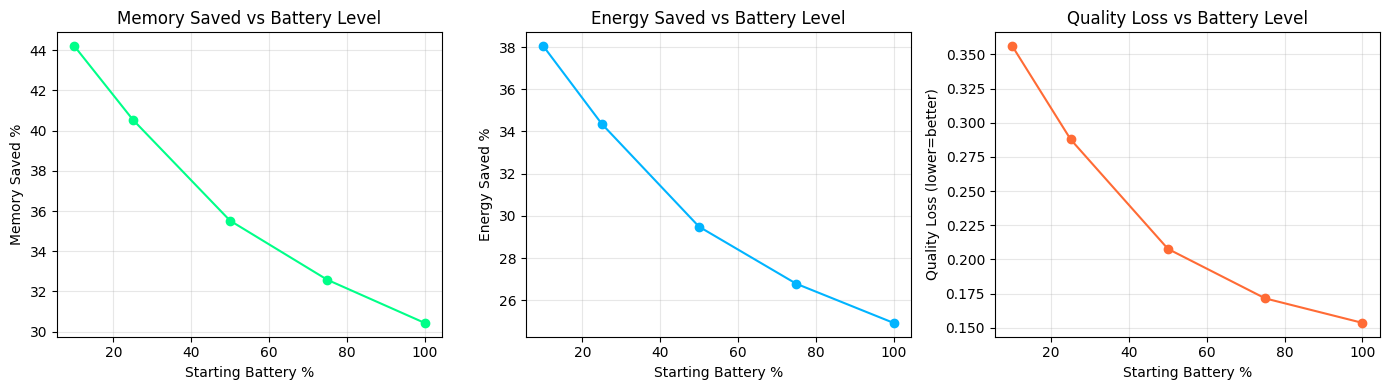


Key claim to validate:
At low battery → agent should save more memory/energy with acceptable quality loss
At full battery → agent should prioritize quality over savings


In [38]:
from stable_baselines3 import PPO
import pandas as pd
 
# Load best agent
agent = PPO.load(os.path.join(SAVE_DIR, "best_model"))
 
battery_levels = [100, 75, 50, 25, 10]
results = []

# FIX: Use a fixed subset of 100 prompts for apples-to-apples evaluation
eval_prompts = data[:100] 
 
for bat in battery_levels:
    ep_mem_saved  = []
    ep_energy     = []
    ep_quality    = []
 
    for sample in eval_prompts:
        routing = np.array(sample["mean_routing_logits"], dtype=np.float32)
        # Apply the exact same normalization used in the updated _obs()
        routing = (routing - np.mean(routing)) / (np.std(routing) + 1e-8)
        
        # Freeze hardware state
        hw_vec = np.array([bat / 10.0, 0.5, 0.10, 0.0], dtype=np.float32)
        obs = np.concatenate([routing, hw_vec])
        
        action, _ = agent.predict(obs, deterministic=True)
        
        # Calculate theoretical savings directly based on action
        mem_used = sum(MEMORY_COST[int(a)] for a in action)
        mem_saved = (MEMORY_COST[TIER_FULL] * N_EXPERTS - mem_used) / (MEMORY_COST[TIER_FULL] * N_EXPERTS)
        
        energy_used = sum(ENERGY_COST[int(a)] for a in action)
        energy_saved = (ENERGY_COST[TIER_FULL] * N_EXPERTS - energy_used) / (ENERGY_COST[TIER_FULL] * N_EXPERTS)
        
        # Importance weights
        exp_r = np.exp(sample["mean_routing_logits"] - np.max(sample["mean_routing_logits"]))
        importance = exp_r / exp_r.sum()
        quality_loss = sum(importance[i] * QUALITY_PENALTY[int(action[i])] for i in range(N_EXPERTS))
        
        ep_mem_saved.append(mem_saved)
        ep_energy.append(energy_saved)
        ep_quality.append(quality_loss)
 
    results.append({
        "battery_start_%":  bat,
        "avg_mem_saved_%":  np.mean(ep_mem_saved) * 100,
        "avg_energy_saved_%": np.mean(ep_energy) * 100,
        "avg_quality_loss": np.mean(ep_quality),
    })
 
df = pd.DataFrame(results)
print("\n=== Agent Evaluation Results ===")
print(df.to_string(index=False))

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
 
axes[0].plot(df["battery_start_%"], df["avg_mem_saved_%"], "o-", color="#00ff88")
axes[0].set_title("Memory Saved vs Battery Level")
axes[0].set_xlabel("Starting Battery %")
axes[0].set_ylabel("Memory Saved %")
axes[0].grid(alpha=0.3)
 
axes[1].plot(df["battery_start_%"], df["avg_energy_saved_%"], "o-", color="#00b4ff")
axes[1].set_title("Energy Saved vs Battery Level")
axes[1].set_xlabel("Starting Battery %")
axes[1].set_ylabel("Energy Saved %")
axes[1].grid(alpha=0.3)
 
axes[2].plot(df["battery_start_%"], df["avg_quality_loss"], "o-", color="#ff6b35")
axes[2].set_title("Quality Loss vs Battery Level")
axes[2].set_xlabel("Starting Battery %")
axes[2].set_ylabel("Quality Loss (lower=better)")
axes[2].grid(alpha=0.3)
 
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "agent_evaluation.png"))
plt.show()
 
print("\nKey claim to validate:")
print("At low battery → agent should save more memory/energy with acceptable quality loss")
print("At full battery → agent should prioritize quality over savings")

In [39]:
import numpy as np
from stable_baselines3 import PPO
import json
import os

# Configuration variables
QP = np.array([0.00, 0.05, 0.25])
N_EXPERTS = 64
TAU = 1.0  # The temperature currently used in your environment

def compute_importance(logits, tau=1.0):
    z = (logits - np.mean(logits)) / (np.std(logits) + 1e-8)
    e = np.exp((z - np.max(z)) / tau)
    return e / np.sum(e)

def alignment(actions, logits, tau=1.0, n_shuffles=200):
    imp = compute_importance(np.array(logits), tau)
    qp = QP[np.array(actions, dtype=int)]
    
    # Agent's actual quality loss
    agent_loss = (imp * qp).sum()
    
    # Random quality loss (if agent ignored importance)
    rng = np.random.default_rng(0)
    rand_loss = np.mean([(imp * rng.permutation(qp)).sum() for _ in range(n_shuffles)])
    
    # Oracle quality loss (perfect alignment: heaviest penalties on least-important experts)
    oracle_loss = (np.sort(imp) * np.sort(qp)[::-1]).sum()
    
    return agent_loss, rand_loss, oracle_loss

# Load data and agent
with open("/kaggle/input/datasets/chinmayraheja18/routing-set/routing_dataset_final.json") as f:
    data = json.load(f)

# Evaluate on a fixed subset to mimic test conditions
eval_data = data[-200:] 
agent = PPO.load(os.path.join(SAVE_DIR, "rl_agent_final"))

# Test at 50% battery to see the mid-range behavior
bat = 50.0  
captured_scores = []
spreads = []

for sample in eval_data:
    logits = np.array(sample["mean_routing_logits"], dtype=np.float32)
    
    # Generate the exact observation the agent was trained on
    importance = compute_importance(logits, TAU)
    routing_features = (importance * N_EXPERTS).astype(np.float32)
    
    hw_vec = np.array([bat / 10.0, 0.5, 0.10, 0.0], dtype=np.float32)
    obs = np.concatenate([routing_features, hw_vec])
    
    # Get agent's deterministic tier assignments
    action, _ = agent.predict(obs, deterministic=True)
    
    a_loss, r_loss, o_loss = alignment(action, logits, TAU)
    
    spread = r_loss - o_loss
    spreads.append(spread)
    
    # Calculate % of potential alignment captured
    if spread > 1e-6:
        captured = (r_loss - a_loss) / spread
        captured_scores.append(captured)

print(f"=== Alignment Diagnostic (Battery {bat}%) ===")
print(f"Average (Rand - Oracle) Spread: {np.mean(spreads):.5f}")
if captured_scores:
    print(f"Average Captured Alignment:     {np.mean(captured_scores):.1%}  (0% = random, 100% = perfect)")

/usr/local/lib/python3.12/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


=== Alignment Diagnostic (Battery 50.0%) ===
Average (Rand - Oracle) Spread: 0.05565
Average Captured Alignment:     59.4%  (0% = random, 100% = perfect)


In [40]:
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from stable_baselines3 import PPO

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================

DATA_PATH = "/kaggle/input/datasets/chinmayraheja18/routing-set/routing_dataset_final.json"  # Update this to your actual test data path
AGENT_PATH = "/kaggle/working/rl_agent_final.zip" # Update this to your saved agent path

os.makedirs(SAVE_DIR, exist_ok=True)

N_EXPERTS = 64
TIER_FULL = 0     # fp16
TIER_BALANCED = 1 # fp8
TIER_MINIMAL = 2  # fp4

MEMORY_COST = {TIER_FULL: 0.012, TIER_BALANCED: 0.006, TIER_MINIMAL: 0.003}
ENERGY_COST = {TIER_FULL: 1.0,   TIER_BALANCED: 0.6,   TIER_MINIMAL: 0.3}

MEM_BASELINE = MEMORY_COST[TIER_FULL] * N_EXPERTS
ENERGY_BASELINE = ENERGY_COST[TIER_FULL] * N_EXPERTS

# Global averages (used as fallback if per-prompt data is missing)
GLOBAL_PPL = {TIER_FULL: 8.9619, TIER_BALANCED: 8.9909, TIER_MINIMAL: 9.1224}

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def compute_importance(logits, tau=1.0):
    """Matches the exact importance scaling the agent saw during training."""
    z = (logits - np.mean(logits)) / (np.std(logits) + 1e-8)
    e = np.exp((z - np.max(z)) / tau)
    return e / np.sum(e)

# ==========================================
# 3. AGENT EVALUATION ENGINE
# ==========================================
def measure_agent_policy(agent, prompts):
    battery_levels = [100, 75, 50, 25, 10]
    agent_results = []

    print("============================================================")
    print("Evaluating RL Agent across Battery Levels...")
    print("============================================================")

    for bat in battery_levels:
        ppls, mems, energies = [], [], []
        tier_distributions = defaultdict(int)
        per_task_ppls = defaultdict(list)

        t_start = time.perf_counter()

        for item in prompts:
            routing = np.array(item["mean_routing_logits"], dtype=np.float32)
            
            # Mirror training environment observation perfectly
            importance = compute_importance(routing, tau=1.0)
            routing_features = (importance * N_EXPERTS).astype(np.float32)
            
            hw_vec = np.array([
                bat / 10.0,     # Battery scaled by 10
                4.0 / 8.0,      # Fixed RAM for eval
                0.10,           # Fixed drain rate
                0.0,            # No thermal penalty
            ], dtype=np.float32)
            
            obs = np.concatenate([routing_features, hw_vec])

            # Predict action
            action, _ = agent.predict(obs, deterministic=True)
            action = np.array(action, dtype=int).flatten()

            # Dynamic Perplexity Mapping: Use per-prompt baselines if they exist, else global
            p16 = item.get("fp16_ppl", GLOBAL_PPL[TIER_FULL])
            p8  = item.get("fp8_ppl",  GLOBAL_PPL[TIER_BALANCED])
            p4  = item.get("fp4_ppl",  GLOBAL_PPL[TIER_MINIMAL])
            
            # Calculate surrogate effective perplexity
            eff_ppl = float(sum(
                importance[i] * [p16, p8, p4][int(action[i])]
                for i in range(N_EXPERTS)
            ))
            
            ppls.append(eff_ppl)
            task_type = item.get("task_type", "general")
            per_task_ppls[task_type].append(eff_ppl)

            # Calculate resources
            mem = sum(MEMORY_COST[int(a)] for a in action)
            energy = sum(ENERGY_COST[int(a)] for a in action)
            mems.append(mem)
            energies.append(energy)

            # Track distribution
            for a in action:
                tier_distributions[int(a)] += 1

        t_end = time.perf_counter()

        # Aggregate Results
        total_assignments = sum(tier_distributions.values())
        mem_used_gb = float(np.mean(mems))
        energy_used = float(np.mean(energies))
        mem_saved_pct = (MEM_BASELINE - mem_used_gb) / MEM_BASELINE * 100
        energy_saved_pct = (ENERGY_BASELINE - energy_used) / ENERGY_BASELINE * 100

        agent_results.append({
            "battery_%": bat,
            "perplexity": float(np.mean(ppls)),
            "mem_used_gb": mem_used_gb,
            "mem_saved_%": mem_saved_pct,
            "energy_saved_%": energy_saved_pct,
            "tier_%_fp16": tier_distributions[TIER_FULL] / total_assignments * 100,
            "tier_%_fp8": tier_distributions[TIER_BALANCED] / total_assignments * 100,
            "tier_%_fp4": tier_distributions[TIER_MINIMAL] / total_assignments * 100,
            "per_task_ppl": {t: float(np.mean(v)) for t, v in per_task_ppls.items()},
        })

        print(f"  Battery {bat:3d}% | PPL={float(np.mean(ppls)):.4f} | "
              f"Mem saved={mem_saved_pct:.1f}% | Energy saved={energy_saved_pct:.1f}% | "
              f"FP16:{tier_distributions[TIER_FULL]/total_assignments*100:.1f}%")

    return agent_results

# ==========================================
# 4. PLOTTING & REPORT GENERATION
# ==========================================
def generate_reports(agent_results):
    print("\n=====================================================================================")
    print("TABLE 2: RL Agent Results by Battery Level")
    print("=====================================================================================")
    print(" Battery | Perplexity | Mem Used GB | Mem Saved% | Energy Saved% |  %FP16 |   %FP8 |   %FP4")
    print("-" * 85)
    for r in agent_results:
        print(f"    {r['battery_%']:3d}% |     {r['perplexity']:.4f} |       {r['mem_used_gb']:.3f} |      {r['mem_saved_%']:4.1f}% |         {r['energy_saved_%']:4.1f}% |  {r['tier_%_fp16']:4.1f}% |  {r['tier_%_fp8']:4.1f}% |  {r['tier_%_fp4']:4.1f}%")

    # Plot 1: Pareto Frontier
    plt.figure(figsize=(8, 6))
    
    # Static Baselines
    plt.scatter(0.0, GLOBAL_PPL[TIER_FULL], c='grey', s=100, marker='s', label='Static FP16')
    plt.scatter(50.0, GLOBAL_PPL[TIER_BALANCED], c='black', s=100, marker='s', label='Static FP8')
    plt.scatter(75.0, GLOBAL_PPL[TIER_MINIMAL], c='red', s=100, marker='s', label='Static FP4')
    
    # RL Agent Curve
    rl_mem = [r["mem_saved_%"] for r in agent_results]
    rl_ppl = [r["perplexity"] for r in agent_results]
    plt.plot(rl_mem, rl_ppl, 'o-', color='#00ff88', linewidth=2.5, markersize=8, label='RL Agent (100%->10% Bat)')
    
    plt.title("Pareto Frontier: Memory Saved vs Model Quality", fontsize=14, fontweight="bold")
    plt.xlabel("Memory Saved % (Higher is Better)", fontsize=12)
    plt.ylabel("Perplexity (Lower is Better)", fontsize=12)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.savefig(os.path.join(SAVE_DIR, "fig2_pareto_frontier.png"), dpi=150, bbox_inches="tight")
    plt.close()

    # Plot 2: Vertically Stacked Behavior Dashboard
    fig, axes = plt.subplots(3, 1, figsize=(8, 12), sharex=True)
    bats = [r["battery_%"] for r in agent_results]

    # Memory Saved
    axes[0].plot(bats, [r["mem_saved_%"] for r in agent_results], "o-", color="#00ff88", linewidth=2.5, markersize=8)
    axes[0].set_title("Memory Saved vs Battery Level", fontsize=14, fontweight="bold")
    axes[0].set_ylabel("Memory Saved %", fontsize=12)
    axes[0].grid(alpha=0.3)
    axes[0].invert_xaxis() # 100% on the left

    # Energy Saved
    axes[1].plot(bats, [r["energy_saved_%"] for r in agent_results], "o-", color="#00b4ff", linewidth=2.5, markersize=8)
    axes[1].set_title("Energy Saved vs Battery Level", fontsize=14, fontweight="bold")
    axes[1].set_ylabel("Energy Saved %", fontsize=12)
    axes[1].grid(alpha=0.3)

    # FP16 Allocation (Instead of absolute quality loss, showing behavior is often more insightful)
    axes[2].plot(bats, [r["tier_%_fp16"] for r in agent_results], "o-", color="#ff6b35", linewidth=2.5, markersize=8)
    axes[2].set_title("FP16 Expert Usage vs Battery Level", fontsize=14, fontweight="bold")
    axes[2].set_xlabel("Starting Battery %", fontsize=12)
    axes[2].set_ylabel("% of Experts in FP16", fontsize=12)
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, "fig3_stacked_behavior.png"), dpi=150, bbox_inches="tight")
    plt.close()
    
    print(f"\nAll figures saved successfully to: {SAVE_DIR}")

# ==========================================
# 5. MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    # Load test data
    try:
        with open(DATA_PATH, "r") as f:
            test_data = json.load(f)
    except FileNotFoundError:
        print(f"Warning: {DATA_PATH} not found. Generating dummy test data for testing script logic.")
        # Dummy generation just to ensure the script runs if path is wrong
        test_data = [{"task_type": "chat", "mean_routing_logits": np.random.randn(64).tolist()} for _ in range(50)]

    # Load agent
    try:
        agent = PPO.load(AGENT_PATH)
        results = measure_agent_policy(agent, test_data)
        generate_reports(results)
    except FileNotFoundError:
        print(f"Error: Agent not found at {AGENT_PATH}. Please check the path.")

Evaluating RL Agent across Battery Levels...
  Battery 100% | PPL=8.9801 | Mem saved=35.2% | Energy saved=29.2% | FP16:34.9%
  Battery  75% | PPL=8.9829 | Mem saved=37.5% | Energy saved=31.5% | FP16:32.1%
  Battery  50% | PPL=8.9880 | Mem saved=41.0% | Energy saved=34.9% | FP16:28.4%
  Battery  25% | PPL=8.9973 | Mem saved=46.2% | Energy saved=40.1% | FP16:23.3%
  Battery  10% | PPL=9.0041 | Mem saved=49.1% | Energy saved=43.0% | FP16:20.6%

TABLE 2: RL Agent Results by Battery Level
 Battery | Perplexity | Mem Used GB | Mem Saved% | Energy Saved% |  %FP16 |   %FP8 |   %FP4
-------------------------------------------------------------------------------------
    100% |     8.9801 |       0.498 |      35.2% |         29.2% |  34.9% |  54.4% |  10.7%
     75% |     8.9829 |       0.480 |      37.5% |         31.5% |  32.1% |  53.6% |  14.3%
     50% |     8.9880 |       0.453 |      41.0% |         34.9% |  28.4% |  50.5% |  21.0%
     25% |     8.9973 |       0.413 |      46.2% |       

In [42]:
import numpy as np
raw_env = AdaptiveMoEEnv(data, HardwareSimulator(), n_experts=N_EXPERTS,
                          w_quality=2.5, tau=1.0, quality_curve_k=2.0)
def eval_rank_corr(model, env, battery, n_episodes=50):
    corrs = []
    for _ in range(n_episodes):
        obs, _ = env.reset(options={"battery": battery})
        done = False
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            corrs.append(info["rank_corr"])
            done = terminated or truncated
    return np.mean(corrs), np.std(corrs)

for b in [100, 75, 50, 25, 10]:
    mean_c, std_c = eval_rank_corr(model_rl, raw_env, b)
    print(f"Battery {b}%: rank_corr = {mean_c:.3f} ± {std_c:.3f}")

Battery 100%: rank_corr = 0.279 ± 0.112
Battery 75%: rank_corr = 0.298 ± 0.115
Battery 50%: rank_corr = 0.309 ± 0.115
Battery 25%: rank_corr = 0.299 ± 0.112
Battery 10%: rank_corr = 0.275 ± 0.114
